# Model v2: exploring the training data

What the data looks like before training model v2, and why the evaluation needs more than the original split.
The loading and splitting code lives in `src/sweet_truth/training/data.py`; this notebook only looks.

Run it from the `notebooks/` folder with the project's environment (`uv sync --all-extras`).

In [1]:
import collections

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sweet_truth.training import data

sns.set_theme(style="whitegrid")

## 1. Labelled ingredients

In [2]:
labels = data.load_ingredients()
ingredients = pd.DataFrame({"ingredient": list(labels), "label": list(labels.values())})
ingredients["group"] = ingredients["ingredient"].map(data.ingredient_group)
print(len(ingredients), "rows,", ingredients["group"].nunique(), "distinct ingredients once case and bracketed notes are ignored")
ingredients["label"].value_counts().rename({0: "other", 1: "sweetener"})

391 rows, 304 distinct ingredients once case and bracketed notes are ignored


label
other        338
sweetener     53
Name: count, dtype: int64

Only about 1 in 7 ingredients is a sweetener, so accuracy alone flatters a model that rarely says "sweetener". The evaluation reports precision, recall and F1 for the sweetener class.

In [3]:
variants = ingredients.groupby("group").filter(lambda g: len(g) > 1).sort_values("group")
print(len(variants), "rows are spelling or case variants of another row, for example:")
variants.head(12)

132 rows are spelling or case variants of another row, for example:


,ingredient,label,group
371,Acesulfame Potassium (Ace-K),1,acesulfame potassium
24,acesulfame potassium,1,acesulfame potassium
150,Acidity Regulator (E260),0,acidity regulator
298,Acidity regulator (339(1)),0,acidity regulator
130,Acidity Regulator (260),0,acidity regulator
324,ACIDITY REGULATOR (INS 330),0,acidity regulator
265,ACIDITY REGULATOR (CITRIC ACID),0,acidity regulator
290,Acidity Regulator (INS 330),0,acidity regulator
336,Acidity Regulator (INS-330),0,acidity regulator
287,Acidity Regulator (330),0,acidity regulator


## 2. What sweetener names look like

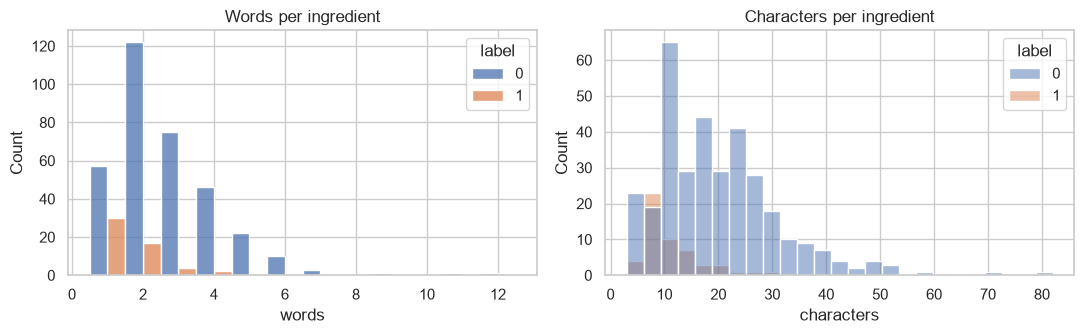

In [4]:
ingredients["words"] = ingredients["ingredient"].str.split().str.len()
ingredients["characters"] = ingredients["ingredient"].str.len()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(ingredients, x="words", hue="label", discrete=True, multiple="dodge", ax=axes[0])
sns.histplot(ingredients, x="characters", hue="label", bins=25, ax=axes[1])
axes[0].set_title("Words per ingredient"); axes[1].set_title("Characters per ingredient")
plt.tight_layout()

In [5]:
sweeteners = ingredients.loc[ingredients["label"] == 1, "group"].unique()
endings = collections.Counter(word[-3:] for name in sweeteners for word in name.split() if len(word) > 4)
pd.DataFrame(endings.most_common(10), columns=["word ending", "sweetener names"])

,word ending,sweetener names
0,ose,8
1,gar,6
2,tol,6
3,rup,6
4,ame,4
5,rin,2
6,act,2
7,ert,2
8,ery,2
9,via,2


Many sweeteners share word pieces (*-ol* in sorbitol, maltitol, xylitol; *-ose* in sucrose, fructose, glucose; *syrup*, *sugar*).
Model v1 treats each whole word as one token, so an unseen word such as *allulose* gives it nothing to go on.
A transformer splits words into sub-word pieces and can use them. That is the improvement model v2 is meant to show.

## 3. The synthetic lists and the original split

In [6]:
lists = data.load_lists()
split = data.notebook_split(lists)
sizes = {name: len(getattr(split, name)) for name in ("train", "validation", "holdout")}
occurrences = {name: len(data.examples_of(getattr(split, name))) for name in sizes}
pd.DataFrame({"lists": sizes, "ingredient occurrences": occurrences})

,lists,ingredient occurrences
train,800,4035
validation,100,512
holdout,100,506


In [7]:
pd.Series([item.label for item in lists]).value_counts().rename({0: "no sweetener", 1: "has a sweetener"})

no sweetener       509
has a sweetener    491
Name: count, dtype: int64

### How many hold-out ingredients are new to the model?

In [8]:
seen = {data.ingredient_group(e.text) for e in data.examples_of(split.train)}
rows = []
for name in ("validation", "holdout"):
    examples = data.examples_of(getattr(split, name))
    unseen = [e for e in examples if data.ingredient_group(e.text) not in seen]
    rows.append({"split": name, "ingredients": len(examples), "never seen in training": len(unseen)})
pd.DataFrame(rows)

,split,ingredients,never seen in training
0,validation,512,0
1,holdout,506,0


None. The 1,000 lists were drawn from the same 392 rows, so every ingredient in the hold-out lists already appears in the training lists.
On this split a model can score almost perfectly by remembering names, which says nothing about how it handles a label it has never seen.
So model v2 is also evaluated on:

1. **unseen-ingredient folds**: 5-fold cross-validation where whole ingredients (all their variants) are held out of training;
2. **a challenge set**: real names that are not in the data, labelled by hand (`data/challenge_ingredients.csv`);
3. **the sample photos** in `images/`.

In [9]:
folds = data.unseen_folds()
pd.DataFrame(
    [{"fold": k, "train": len(tr), "test": len(te), "sweeteners in test": sum(e.label for e in te)}
     for k, (tr, te) in enumerate(folds)]
)

,fold,train,test,sweeteners in test
0,0,319,72,7
1,1,316,75,16
2,2,308,83,8
3,3,313,78,11
4,4,308,83,11


## 4. The challenge set

In [10]:
challenge = pd.read_csv(data.CHALLENGE_CSV)
challenge["label"].value_counts().rename({0: "other", 1: "sweetener"})

label
sweetener    24
other        22
Name: count, dtype: int64

In [11]:
challenge

,ingredient,label,note
0,allulose,1,rare sugar
1,tagatose,1,rare sugar
2,trehalose,1,sugar
3,isomaltulose,1,sugar; looks like isomalt (in the dataset)
4,coconut sugar,1,sugar
5,palm sugar,1,sugar
6,date syrup,1,syrup
7,brown rice syrup,1,syrup
8,golden syrup,1,syrup
9,treacle,1,syrup
